

* **Тема и источник:** Рынок подержанных автомобилей. Датасет взят с Kaggle (`Car details v3.csv`, автор Neha Birla, ссылка: https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho, скачан 19.11.2026, лицензия DbCL v1.0).
* **Единица наблюдения:** Одна строка — это одно объявление о продаже подержанного автомобиля.

**Используемые столбцы:**
* `name` — марка и модель автомобиля (текст).
* `year` — год выпуска (год, целое число).
* `selling_price` — цена продажи в объявлении (индийские рупии, INR).
* `km_driven` — пробег автомобиля (километры, км).
* `fuel` — тип топлива (`Diesel`, `Petrol`, `CNG`, `LPG`).
* `transmission` — коробка передач (`Manual`, `Automatic`).
* `seller_type` — тип продавца (`Individual`, `Dealer`, `Trustmark Dealer`).
* `owner` — какой по счёту владелец (`First Owner`, `Second Owner` и др.).

**Вопросы исследования:**
1. Какие типы топлива встречаются чаще всего и какую долю (в %) от всех уникальных объявлений занимают дизельные и бензиновые авто?
2. Насколько различаются средняя и медианная цена продажи между механикой (`Manual`) и автоматом (`Automatic`)?
3. Как меняется медианная цена при переходе к более свежим авто (от 2016 года выпуска и от 2018 года)?

**Кому полезен анализ:** Покупателям подержанных машин, чтобы прикинуть реальный бюджет по медианным ценам, и автодилерам для первичной оценки авто при выкупе.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

raw_df = pd.read_csv( "Car details v3.csv")
df = raw_df.copy()

print("Размер:", raw_df.shape)
print("Столбцы:", raw_df.columns.tolist())


Размер: (8128, 13)
Столбцы: ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats']


In [11]:
raw_df.dtypes

,0
name,object
year,int64
selling_price,int64
km_driven,int64
fuel,object
seller_type,object
transmission,object
owner,object
mileage,object
engine,object


In [13]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 825.6+ KB


In [16]:
raw_df.head(10)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0
5,Hyundai Xcent 1.2 VTVT E Plus,2017,440000,45000,Petrol,Individual,Manual,First Owner,20.14 kmpl,1197 CC,81.86 bhp,113.75nm@ 4000rpm,5.0
6,Maruti Wagon R LXI DUO BSIII,2007,96000,175000,LPG,Individual,Manual,First Owner,17.3 km/kg,1061 CC,57.5 bhp,"7.8@ 4,500(kgm@ rpm)",5.0
7,Maruti 800 DX BSII,2001,45000,5000,Petrol,Individual,Manual,Second Owner,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0
8,Toyota Etios VXD,2011,350000,90000,Diesel,Individual,Manual,First Owner,23.59 kmpl,1364 CC,67.1 bhp,170Nm@ 1800-2400rpm,5.0
9,Ford Figo Diesel Celebration Edition,2013,200000,169000,Diesel,Individual,Manual,First Owner,20.0 kmpl,1399 CC,68.1 bhp,160Nm@ 2000rpm,5.0


In [17]:
raw_df.sample(5, random_state=42)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
1971,Honda City 1.5 GXI,2004,198000,110000,Petrol,Individual,Manual,Third Owner,12.8 kmpl,1493 CC,100 bhp,13.1kgm@ 4600rpm,5.0
4664,Tata Safari Storme EX,2014,500000,291977,Diesel,Individual,Manual,First Owner,14.0 kmpl,2179 CC,138.1 bhp,320Nm@ 1700-2700rpm,7.0
5448,Maruti Ritz VDi,2016,425000,70000,Diesel,Individual,Manual,First Owner,23.2 kmpl,1248 CC,73.94 bhp,190Nm@ 2000rpm,5.0
3333,Honda City 2017-2020 VTEC,2006,150000,120000,Petrol,Individual,Manual,Second Owner,16.9 kmpl,1497 CC,100 bhp,"13.5@ 4,800(kgm@ rpm)",5.0
2316,Maruti Swift VDI,2013,525000,69000,Diesel,Individual,Manual,Second Owner,22.9 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0


В таблице 8128 строк и 13 столбцов. Числовые типы (`int64`, `float64`) у 4 полей: `year`, `selling_price`, `km_driven`, `seats`. Остальные 9 столбцов имеют тип `object`. Внимания требуют `mileage`, `engine`, `max_power` и `torque` — там записаны числа вместе с единицами измерения, а также есть пропуски.

Первые строки не заменяют случайную выборку, потому что при выгрузке таблица могла быть отсортирована. Параметр `random_state=42` фиксирует генератор случайных чисел, чтобы при повторном запуске выпадали те же 5 строк.

In [25]:
df["selling_price"]

,selling_price
0,450000
1,370000
2,158000
3,225000
4,130000
...,...
8123,320000
8124,135000
8125,382000
8126,290000


In [27]:
df[["selling_price"]]

,selling_price
0,450000
1,370000
2,158000
3,225000
4,130000
...,...
8123,320000
8124,135000
8125,382000
8126,290000


In [32]:
price_series = df["selling_price"]
price_df = df[["selling_price"]]
print("Одна пара скобок:", type(price_series).__name__)
print("Список колонок:", type(price_df).__name__)

Одна пара скобок: Series
Список колонок: DataFrame


In [34]:
df.iloc[0:10, 0:3]

,name,year,selling_price
0,Maruti Swift Dzire VDI,2014,450000
1,Skoda Rapid 1.5 TDI Ambition,2014,370000
2,Honda City 2017-2020 EXi,2006,158000
3,Hyundai i20 Sportz Diesel,2010,225000
4,Maruti Swift VXI BSIII,2007,130000
5,Hyundai Xcent 1.2 VTVT E Plus,2017,440000
6,Maruti Wagon R LXI DUO BSIII,2007,96000
7,Maruti 800 DX BSII,2001,45000
8,Toyota Etios VXD,2011,350000
9,Ford Figo Diesel Celebration Edition,2013,200000


In [35]:
df.iloc[0:50:5, 0:3]

,name,year,selling_price
0,Maruti Swift Dzire VDI,2014,450000
5,Hyundai Xcent 1.2 VTVT E Plus,2017,440000
10,Renault Duster 110PS Diesel RxL,2014,500000
15,Mahindra KUV 100 mFALCON G80 K8 5str,2016,400000
20,Mahindra Verito 1.5 D4 BSIII,2011,174000
25,Maruti Baleno Delta 1.2,2016,575000
30,Maruti Vitara Brezza LDi Option,2017,670000
35,Maruti Alto 800 CNG LXI Optional,2019,330000
40,Maruti 800 Std,2012,150000
45,Maruti Vitara Brezza VDi,2018,819999


In [36]:
df.loc[df["transmission"] == "Automatic", ["name", "year", "selling_price", "km_driven"]].head(5)

,name,year,selling_price,km_driven
41,Jeep Compass 1.4 Limited Plus BSIV,2019,2100000,5000
44,Maruti Swift Dzire VXi AT,2018,675000,23300
49,Mercedes-Benz B Class B180,2014,1450000,27800
55,Toyota Innova Crysta 2.8 ZX AT BSIV,2016,1650000,127700
57,Audi A6 2.0 TDI Technology,2013,1750000,33900


In [39]:
top10_price = df.loc[df["selling_price"].notna()].sort_values("selling_price", ascending=False)
top10_price[["name", "year", "selling_price", "fuel"]].head(10)

,name,year,selling_price,fuel
170,Volvo XC90 T8 Excellence BSIV,2017,10000000,Petrol
2938,BMW X7 xDrive 30d DPE,2020,7200000,Diesel
4952,Audi A6 35 TFSI Matrix,2019,6523000,Petrol
4950,Audi A6 35 TFSI Matrix,2019,6223000,Petrol
4766,BMW 6 Series GT 630d Luxury Line,2018,6000000,Diesel
1071,BMW 6 Series GT 630d Luxury Line,2018,6000000,Diesel
5258,Mercedes-Benz S-Class S 350 CDI,2017,6000000,Diesel
4101,BMW 6 Series GT 630d Luxury Line,2018,6000000,Diesel
136,Mercedes-Benz S-Class S 350 CDI,2017,6000000,Diesel
7713,Mercedes-Benz S-Class S 350 CDI,2017,6000000,Diesel


In [40]:
df.sort_values(["fuel", "selling_price"], ascending=[True, False])[["name", "fuel", "selling_price"]].head(10)

,name,fuel,selling_price
5749,Maruti Ertiga VXI CNG Limited Edition,CNG,545000
2527,Maruti Wagon R LXI CNG,CNG,459999
6488,Maruti Wagon R LXI CNG Optional,CNG,459999
1225,Maruti Eeco CNG 5 Seater AC BSIV,CNG,450000
1350,Maruti Eeco CNG 5 Seater AC BSIV,CNG,450000
2767,Maruti Wagon R LXI CNG,CNG,450000
5789,Maruti Alto K10 LXI CNG,CNG,430000
3853,Maruti Wagon R LXI CNG,CNG,420000
402,Maruti Eeco CNG 5 Seater AC,CNG,409999
3200,Maruti Wagon R LXI CNG,CNG,400000


`loc` ищет строки и столбцы по их меткам (именам и значениям индекса) и включает правую границу среза, а `iloc` работает строго по числовым позициям с нуля и правую границу не включает. Выражение `head(10).dropna()` может вернуть меньше 10 строк, потому что сначала берутся первые 10 записей, а затем из них выбрасываются строки, где есть хотя бы один пропуск.

In [42]:
missing_before = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2)
})
missing_before.sort_values("missing_count", ascending=False)

,missing_count,missing_pct
torque,222,2.73
seats,221,2.72
engine,221,2.72
mileage,221,2.72
max_power,215,2.65
fuel,0,0.00
km_driven,0,0.00
selling_price,0,0.00
year,0,0.00
name,0,0.00


In [44]:
print("Полных повторов строк:", df.duplicated().sum())
df.loc[df.duplicated(keep=False)].sort_values(["name", "year"]).head(4)

Полных повторов строк: 1202


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
1977,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.0
7324,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.0
2129,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.0
7775,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.0


In [46]:
df = df.drop_duplicates().copy()
assert df.duplicated().sum() == 0
print("Строк до:", len(raw_df), "| Строк после:", len(df))

Строк до: 8128 | Строк после: 6926


In [48]:
print("Цена min / max:", df["selling_price"].min(), df["selling_price"].max())
print("Пробег min / max:", df["km_driven"].min(), df["km_driven"].max())
df.loc[(df["km_driven"] <= 10) | (df["km_driven"] > 500000), ["name", "year", "selling_price", "km_driven", "owner"]]

Цена min / max: 29999 10000000
Пробег min / max: 1 2360457


,name,year,selling_price,km_driven,owner
1810,Mahindra XUV500 W6 2WD,2012,500000,1500000,First Owner
3486,Hyundai i20 Asta 1.2,2007,550000,2360457,Second Owner
3508,Maruti Wagon R LXI Minor,2010,194000,577414,Second Owner
7913,Maruti Eeco 5 STR With AC Plus HTR CNG,2011,209000,1,Fourth & Above Owner


В исходной таблице нашлось 1202 полных дубля по всем 13 столбцам (одинаковые модель, год, цена, пробег и характеристики) — это повторные выгрузки одних и тех же объявлений, поэтому их удалили через `drop_duplicates()`. Число строк сократилось с 8128 до 6926.

Пропуски есть только в 5 технических столбцах (`mileage`, `engine`, `max_power`, `torque`, `seats` — около 3% строк). Удалять все строки с пропусками или заполнять их нулями нельзя, так как основные поля (`selling_price`, `km_driven`, `fuel`, `year`) заполнены на 100% — поэтому оставляем пропуски как есть и будем исключать их только при необходимости через `subset`. В `km_driven` встретились аномальные значения (1 км у машины 2011 года и 2.36 млн км), но отрицательных цен или нулей нет, поэтому строки не удалялись, чтобы не исказить реальную выгрузку.

In [50]:
display(df[["selling_price", "km_driven"]].describe().round(2))

,selling_price,km_driven
count,6926.00,6926.00
mean,517270.68,73995.68
std,519766.99,58358.10
min,29999.00,1.00
25%,250000.00,40000.00
50%,400000.00,70000.00
75%,633500.00,100000.00
max,10000000.00,2360457.00


In [52]:
for col in ["selling_price", "km_driven"]:
    print(f"--- {col} ---")
    print("Известных значений:", df[col].count())
    print("Среднее:", round(df[col].mean(), 2))
    print("Медиана:", df[col].median())
    print("Мин / Макс:", df[col].min(), "/", df[col].max())
    print("Стандартное отклонение:", round(df[col].std(), 2))
    display(df[col].quantile([0.25, 0.5, 0.75, 0.9]).round(2))

--- selling_price ---
Известных значений: 6926
Среднее: 517270.68
Медиана: 400000.0
Мин / Макс: 29999 / 10000000
Стандартное отклонение: 519766.99


,selling_price
0.25,250000.0
0.50,400000.0
0.75,633500.0
0.90,900000.0


--- km_driven ---
Известных значений: 6926
Среднее: 73995.68
Медиана: 70000.0
Мин / Макс: 1 / 2360457
Стандартное отклонение: 58358.1


,km_driven
0.25,40000.0
0.50,70000.0
0.75,100000.0
0.90,120000.0


In [57]:
fuel_counts = df["fuel"].value_counts(dropna=False)
fuel_pct = (df["fuel"].value_counts(normalize=True,dropna=False) * 100).round(1)
pd.DataFrame({"count": fuel_counts, "percent": fuel_pct})

,count,percent
fuel,,
Diesel,3755,54.2
Petrol,3077,44.4
CNG,56,0.8
LPG,38,0.5


В расчётах участвовали все 6926 уникальных объявлений (пропусков в цене и пробеге нет). Средняя цена равна 517 270.68 INR, а медиана заметно ниже — 400 000 INR: среднее тянут вверх редкие дорогие автомобили стоимостью до 10 000 000 INR. Квантиль 90% (p90) по цене равен 900 000 INR — это значит, что 90% объявлений в наборе стоят не дороже 900 000 INR, и только 10% дороже.

По типу топлива среди всех 6926 объявлений (знаменатель — 6926) лидируют дизельные авто: 3755 машин (54.2%), на втором месте бензиновые — 3077 машин (44.4%), а на CNG и LPG приходится суммарно 1.3% (94 машины).

In [58]:
diesel_auto = df.loc[(df["fuel"] == "Diesel") & (df["transmission"] == "Automatic")]
print("Дизельных авто на автомате:", len(diesel_auto))

Дизельных авто на автомате: 298


In [59]:
gas_cars = df.loc[df["fuel"].isin(["CNG", "LPG"])]
print("Авто на газе (CNG или LPG):", len(gas_cars))

Авто на газе (CNG или LPG): 94


In [61]:
manual_cars = df.loc[df["transmission"] == "Manual"]
auto_cars = df.loc[df["transmission"] == "Automatic"]

In [63]:
for name_grp, grp in [("Manual", manual_cars), ("Automatic", auto_cars)]:
    print(f"{name_grp}: строк={len(grp)}, известных цен={grp['selling_price'].count()}, "
          f"среднее={round(grp['selling_price'].mean(), 1)}, медиана={grp['selling_price'].median()}")

Manual: строк=6342, известных цен=6342, среднее=444299.1, медиана=385000.0
Automatic: строк=584, известных цен=584, среднее=1309712.3, медиана=850000.0


In [65]:
fresh_2016 = df.loc[df["year"] >= 2016]
fresh_2018 = df.loc[df["year"] >= 2018]
print("\nПорог year >= 2016: строк =", len(fresh_2016), "| медианная цена =", fresh_2016["selling_price"].median())
print("Порог year >= 2018: строк =", len(fresh_2018), "| медианная цена =", fresh_2018["selling_price"].median())


Порог year >= 2016: строк = 2519 | медианная цена = 635000.0
Порог year >= 2018: строк = 1018 | медианная цена = 695000.0


Автомобили с автоматом (`Automatic`) в этом наборе стоят заметно дороже механики (`Manual`): медианная цена 850 000 INR против 385 000 INR, а средняя — 1 309 712.3 INR против 444 299.1 INR. Ограничение сравнения в том, что группы сильно неравны по размеру: 6342 машины на механике и только 584 на автомате (к тому же в сегменте автомата чаще встречаются премиальные марки).

В мини-эксперименте при сдвиге порога года выпуска с `year >= 2016` до `year >= 2018` число подходящих объявлений сократилось с 2519 до 1018 (более чем в 2.4 раза), при этом медианная цена выросла с 635 000 до 695 000 INR.

In [67]:
assert df["year"].notna().all()
df["car_age"] = 2020 - df["year"]
display(df[["name", "year", "car_age"]].head(5))

,name,year,car_age
0,Maruti Swift Dzire VDI,2014,6
1,Skoda Rapid 1.5 TDI Ambition,2014,6
2,Honda City 2017-2020 EXi,2006,14
3,Hyundai i20 Sportz Diesel,2010,10
4,Maruti Swift VXI BSIII,2007,13


In [69]:
fuel_report = df.groupby("fuel", dropna=False, as_index=False).agg(
    listings=("name", "size"),
    known_price=("selling_price", "count"),
    mean_price=("selling_price", "mean"),
    median_price=("selling_price", "median"),
    max_price=("selling_price", "max")
).sort_values("listings", ascending=False)

In [71]:
assert fuel_report["listings"].sum() == len(df)
fuel_report.round(1)

,fuel,listings,known_price,mean_price,median_price,max_price
1,Diesel,3755,3755,639727.8,520000.0,7200000
3,Petrol,3077,3077,375689.0,310000.0,10000000
0,CNG,56,56,300499.9,320000.0,545000
2,LPG,38,38,200421.1,195500.0,375000


Функция `size` считает общее количество строк (объявлений) в каждой группе, а `count` — только заполненные (непустые) значения столбца `selling_price`. В нашем отчёте `listings` и `known_price` совпали во всех группах, потому что в столбце `selling_price` нет ни одного пропуска. Сумма размеров всех групп равна 6926 — это совпадает с общим числом строк рабочей таблицы.

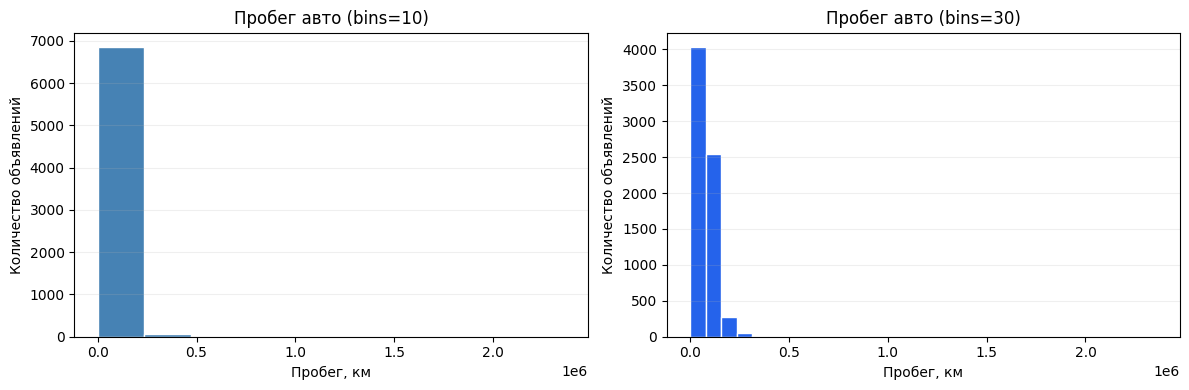

In [78]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["km_driven"], bins=10, color="steelblue", edgecolor="white")
axes[0].set_title("Пробег авто (bins=10)")
axes[0].set_xlabel("Пробег, км")
axes[0].set_ylabel("Количество объявлений")
axes[0].grid(axis="y", alpha=0.2)

axes[1].hist(df["km_driven"], bins=30, color="#2563EB", edgecolor="white")
axes[1].set_title("Пробег авто (bins=30)")
axes[1].set_xlabel("Пробег, км")
axes[1].set_ylabel("Количество объявлений")
axes[1].grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

При увеличении числа корзин с `bins=10` до `bins=30` столбцы становятся уже и детальнее показывают пик объявлений в районе 50 000–80 000 км, тогда как на `bins=10` почти вся основная масса сливается в первый широкий столбец из-за редких выбросов справа (до 2.36 млн км).

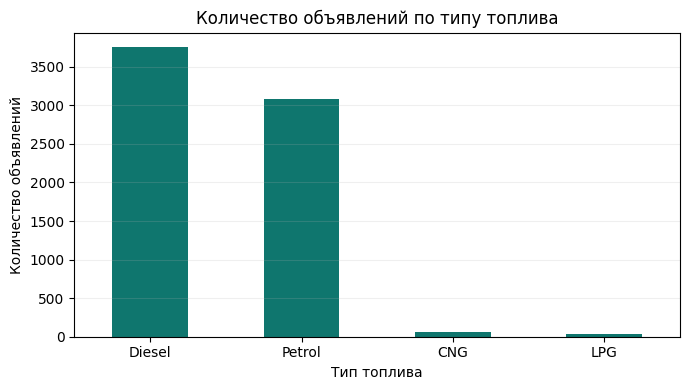

In [79]:
fuel_freq = df["fuel"].value_counts()
fig, ax = plt.subplots(figsize=(7, 4))
fuel_freq.plot.bar(ax=ax, color="#0F766E", rot=0)
ax.set_title("Количество объявлений по типу топлива")
ax.set_xlabel("Тип топлива")
ax.set_ylabel("Количество объявлений")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

На рынке подержанных авто в этом наборе доминируют дизельные (3755) и бензиновые (3077) машины, а газовые модификации (CNG и LPG) представлены единичными объявлениями.

,fuel,listings,median_price
1,Diesel,3755,520000.0
3,Petrol,3077,310000.0
0,CNG,56,320000.0
2,LPG,38,195500.0


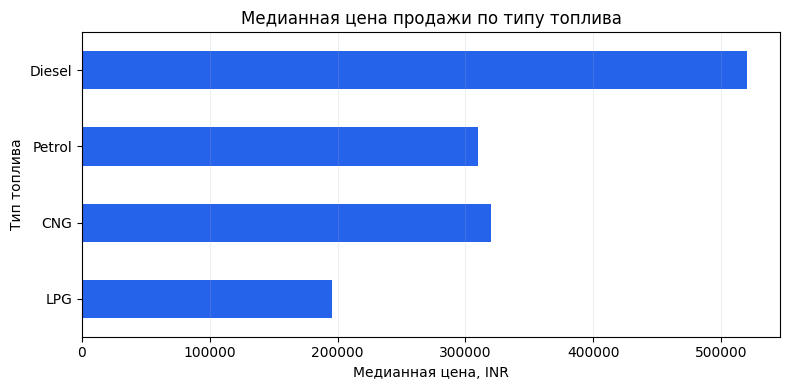

In [80]:
display(fuel_report[["fuel", "listings", "median_price"]])

fig, ax = plt.subplots(figsize=(8, 4))
fuel_report.plot.barh(x="fuel", y="median_price", ax=ax, color="#2563EB", legend=False)
ax.invert_yaxis()
ax.set_title("Медианная цена продажи по типу топлива")
ax.set_xlabel("Медианная цена, INR")
ax.set_ylabel("Тип топлива")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

Самая высокая медианная цена у дизельных автомобилей — 520 000 INR против 310 000 INR у бензиновых, но при сравнении с LPG (195 500 INR) важно учитывать малый размер группы LPG (всего 38 машин).

In [81]:
from pathlib import Path

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

report_to_save = fuel_report.round({"mean_price": 1, "median_price": 1})
report_path = OUTPUT_DIR / "group_report.csv"

report_to_save.to_csv(report_path, index=False, encoding="utf-8-sig")
report_back = pd.read_csv(report_path)

assert len(report_back) == len(report_to_save)
assert report_back.columns.tolist() == report_to_save.columns.tolist()
assert np.isclose(report_back["listings"].sum(), report_to_save["listings"].sum())

display(report_back)
print("Версии библиотек — pandas:", pd.__version__, "| NumPy:", np.__version__, "| Matplotlib:", plt.matplotlib.__version__)

,fuel,listings,known_price,mean_price,median_price,max_price
0,Diesel,3755,3755,639727.8,520000.0,7200000
1,Petrol,3077,3077,375689.0,310000.0,10000000
2,CNG,56,56,300499.9,320000.0,545000
3,LPG,38,38,200421.1,195500.0,375000


Версии библиотек — pandas: 2.2.3 | NumPy: 2.4.6 | Matplotlib: 3.10.0


Для повторения анализа положите файл `Car details v3.csv` в папку `data/` рядом с ноутбуком и выполните `Restart Kernel -> Run All`. Итоговый отчёт сохраняется в `output/group_report.csv`, а график — в `output/chart.png`.



**Ответы на вопросы исследования:**
1. В очищенном наборе из 6926 объявлений чаще всего встречаются дизельные (3755 шт., 54.2%) и бензиновые (3077 шт., 44.4%) автомобили.
2. Автомобили с автоматической коробкой передач имеют медианную цену 850 000 INR (средняя 1 309 712.3 INR), тогда как с механической — 385 000 INR (средняя 444 299.1 INR).
3. При ужесточении фильтра по году выпуска с `year >= 2016` до `year >= 2018` медианная цена вырастает с 635 000 до 695 000 INR, а выборка сужается с 2519 до 1018 машин.

**Ограничения и следующий вопрос:**
* **Ограничение 1:** В таблице указана цена из объявления, а не фактическая цена закрытой сделки после торга.
* **Ограничение 2:** Сильный перекос размеров групп (например, 6342 авто на механике против 584 на автомате и 38 на LPG) не позволяет делать выводы о причинах разницы цен только по одному признаку.
* **Следующий вопрос:** Как различается медианная цена между частными продавцами (`Individual`) и автодилерами (`Dealer`) внутри одного года выпуска?

**Журнал работы с ИИ:**

| Моя задача / вопрос | Что подсказал ИИ | Как я проверил | Что теперь могу объяснить |
| :--- | :--- | :--- | :--- |
| Как проверить, есть ли в датасете полные повторы, и убрать их без потери исходника? | Использовать `df.duplicated().sum()`, посмотреть дубли через `keep=False` и сохранить результат в копию через `drop_duplicates().copy()`. | Запустил код, увидел 1202 дубля и проверил `len(raw_df)` (8128) и `len(df)` (6926). | Почему нельзя перезаписывать `raw_df` и как убедиться, что дубли действительно идентичны по всем полям. |
| В чём разница между `size` и `count` внутри `groupby().agg()`? | `size` считает все строки группы вместе с пропусками, а `count` — только заполненные значения конкретного столбца. | Сравнил `listings=("name", "size")` и `known_price=("selling_price", "count")` в групповом отчёте. | Когда `size` и `count` совпадают (если в столбце нет `NaN`) и зачем проверять сумму строк после группировки. |
| Как настроить горизонтальный график в Matplotlib и сохранить его в файл? | Использовать `plot.barh()`, `ax.invert_yaxis()` для сортировки сверху вниз и вызвать `plt.savefig()` строго до `plt.show()`. | Построил график, поменял цвет и проверил, что файл `output/chart.png` не пустой. | Если вызвать `savefig()` после `show()`, картинка сохранится пустой, так как `show()` очищает фигуру. |